<a href="https://colab.research.google.com/github/priyansh-commits/Deep_Learning/blob/main/stock_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip -q install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization

import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

Price            Close
Date                  
2015-01-01  189.125381
2015-01-02  188.624802
2015-01-05  186.558685
2015-01-06  178.091812
2015-01-07  181.968491
(2716, 1)


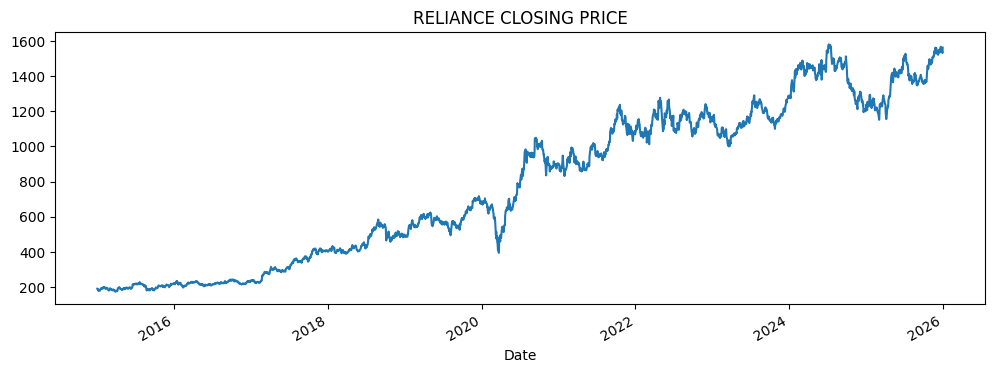

In [113]:
df = yf.download(
    "RELIANCE.NS",
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Handle yfinance's possible MultiIndex columns
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Close"]].dropna()

print(df.head())
print(df.shape)

df["Close"].plot(figsize=(12, 4), title="RELIANCE CLOSING PRICE")
plt.show()

In [89]:
prices = df[["Close"]].values

split_idx = int(len(prices) * 0.8)

train_prices = prices[:split_idx]
test_prices = prices[split_idx:]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_prices)
test_scaled = scaler.transform(test_prices)

print("Train samples:", len(train_scaled))
print("Test samples:", len(test_scaled))

Train samples: 2172
Test samples: 544


In [90]:
days=60

In [91]:
def create_sequences(data, window=60):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])

    X = np.array(X)
    y = np.array(y)

    return X.reshape(-1, window, 1), y

X_train, y_train = create_sequences(train_scaled)


test_context = np.vstack([train_scaled[-days:], test_scaled])
X_test, y_test = create_sequences(test_context)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(2112, 60, 1) (2112,)
(544, 60, 1) (544,)


In [92]:

def build_model(model_type):
    model = Sequential()

    if model_type == "SimpleRNN":
        model.add(SimpleRNN(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    elif model_type == "LSTM":
        model.add(LSTM(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    elif model_type == "GRU":
        model.add(GRU(
            32,
            # return_sequences=True,
            input_shape=(days, 1)
        ))


    else:
        raise ValueError(f"Unknown model type: {model_type}")

    model.add(Dropout(0.15))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(1))

    model.compile(optimizer="adam", loss="mse")

    return model

In [93]:
models = {}
histories = {}
predictions = {}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True
)

for name in ["SimpleRNN", "LSTM", "GRU"]:
    print(f"\nTraining {name}...")

    model = build_model(name)

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    models[name] = model
    histories[name] = history

    # Generate predictions from THIS model
    pred_scaled = model.predict(X_test, verbose=0)

    print(name, "raw prediction shape:", pred_scaled.shape)

    # Convert scaled values back to actual stock prices
    pred_scaled = pred_scaled.reshape(-1, 1)
    predictions[name] = scaler.inverse_transform(
        pred_scaled
    ).ravel()

    print(name, "final prediction count:", len(predictions[name]))


Training SimpleRNN...
Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0080 - val_loss: 0.0072
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0024 - val_loss: 0.0014
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0020 - val_loss: 0.0028
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0015 - val_loss: 0.0023
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0023
SimpleRNN raw prediction shape: (544, 1)
SimpleRNN final prediction count: 544

Training LSTM...
Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0027 - val_loss: 0.0011
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0057 - val_loss: 0.0023
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0016 - val_loss: 9.2853e-04
Epoch 5/30
53/53 ━━━━━━━━━

In [94]:
print("Actual count:", len(actual))

for name, pred in predictions.items():
    print(name, len(pred))

Actual count: 554
SimpleRNN 544
LSTM 544
GRU 544


In [95]:
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

results = []

for name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("MAE")

print(results_df)

       Model         MAE        RMSE
1       LSTM   90.468594  101.954339
0  SimpleRNN  108.734242  119.476590
2        GRU  114.023394  122.511118


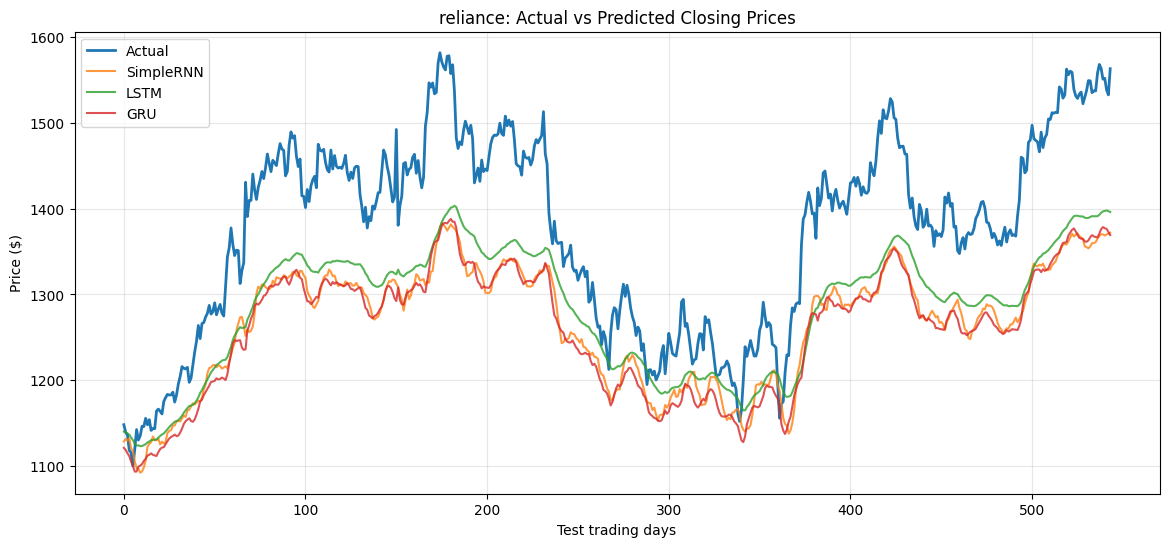

In [114]:
plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual", linewidth=2)

for name, pred in predictions.items():
    plt.plot(pred, label=name, alpha=0.8)

plt.title("reliance: Actual vs Predicted Closing Prices")
plt.xlabel("Test trading days")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

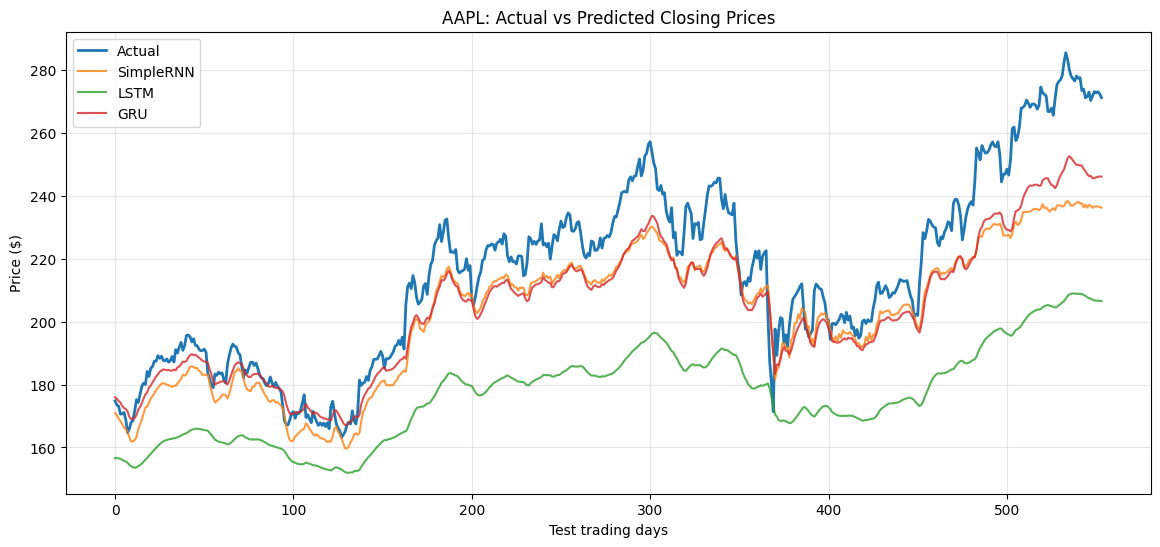

In [97]:
close_prices = df["Close"].to_numpy(dtype=float)

train_close = close_prices[:split_idx]
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Create the naive baseline
# Predict that tomorrow's close = today's close
naive_pred = np.concatenate([
    train_close[-1:],
    actual[:-1]
])

# 2. Add baseline to your existing predictions
all_predictions = predictions.copy()
all_predictions["Naive Baseline"] = naive_pred

# 3. Compare all models
results = []

for name, pred in all_predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE").to_string(index=False))

         Model        MAE       RMSE
Naive Baseline  12.884843  17.915273
          LSTM  90.468594 101.954339
     SimpleRNN 108.734242 119.476590
           GRU 114.023394 122.511118


**FOR 30 DAYS**


```
         Model       MAE      RMSE
Naive Baseline  2.448790  3.625660
           GRU  3.152632  4.489642
          LSTM 24.301933 27.537755
     SimpleRNN 28.474677 33.081692
```


```


Actual first 5: [187.08908081 187.66207886 188.93658447 187.14836121 191.09028625]
Naive first 5: [176.33505249 187.08908081 187.66207886 188.93658447 187.14836121]
GRU first 5: [189.52892 189.1151  189.13033 189.74525 189.30013]
```






**FOR 60 DAYS**
```
     Model       MAE      RMSE
Naive Baseline  2.383065  3.525843
           GRU 11.473411 14.031575
     SimpleRNN 12.921555 16.024301
          LSTM 38.046757 41.011687
```


```
Actual first 5: [174.78599548 173.49351501 173.11857605 170.57299805 170.69136047]
Naive first 5: [176.33505249 174.78599548 173.49351501 173.11857605 170.57299805]
GRU first 5: [175.9444  175.45439 174.77417 174.23096 173.1699 ]
```


naive prediction were better than all neural networks just so it is complext doesnt mean it si better


In [98]:
print("Actual first 5:", actual[:5])
print("Naive first 5:", naive_pred[:5])
print("GRU first 5:", predictions["GRU"][:5])

print("Lengths:")
print("Actual:", len(actual))
print("Naive:", len(naive_pred))
print("GRU:", len(predictions["GRU"]))

Actual first 5: [1148.1541748  1139.33544922 1135.85253906 1118.11633301 1115.52258301]
Naive first 5: [1163.59301758 1148.1541748  1139.33544922 1135.85253906 1118.11633301]
GRU first 5: [1121.1753 1118.7004 1114.879  1111.4823 1105.1105]
Lengths:
Actual: 544
Naive: 544
GRU: 544


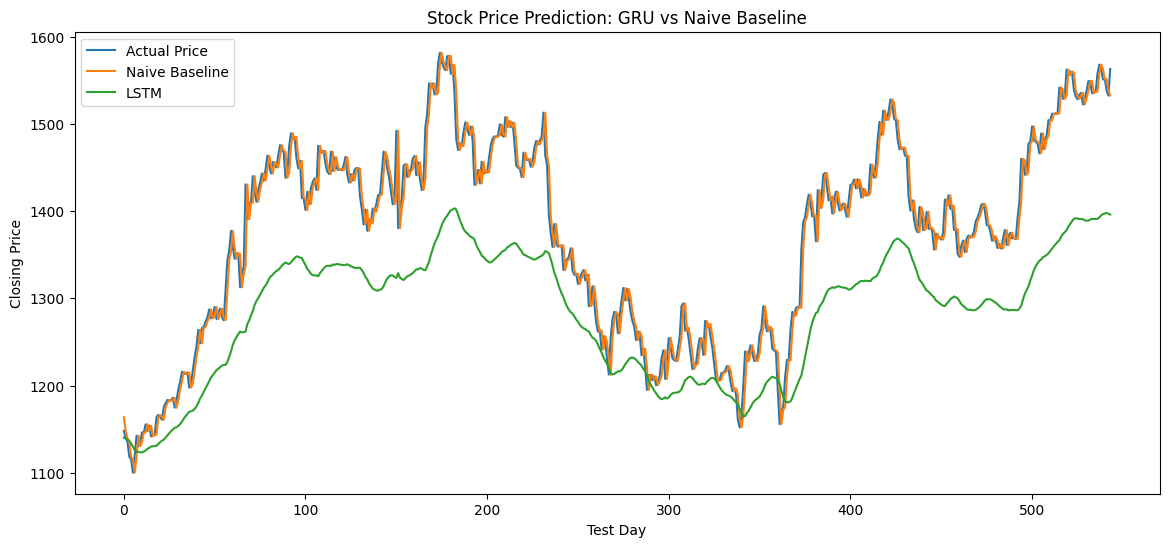

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual Price")
plt.plot(naive_pred, label="Naive Baseline")
plt.plot(predictions["LSTM"], label="LSTM")

plt.title("Stock Price Prediction: GRU vs Naive Baseline")
plt.xlabel("Test Day")
plt.ylabel("Closing Price")
plt.legend()
plt.show()

comparing with chronos pre trained model

In [101]:
!pip install -q git+https://github.com/amazon-science/chronos-forecasting.git

import torch
import numpy as np
from chronos import BaseChronosPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

chronos = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-tiny",
    device_map=device
)

print("Chronos loaded successfully!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cpu


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 34.6MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Chronos loaded successfully!


In [102]:
close_prices = df["Close"].to_numpy(dtype=np.float32)

train_close = close_prices[:split_idx]
test_close = close_prices[split_idx:]

print("Training prices:", len(train_close))
print("Test prices:", len(test_close))
print("First test prices:", test_close[:5])

Training prices: 2172
Test prices: 544
First test prices: [1148.1542 1139.3354 1135.8525 1118.1163 1115.5226]


In [115]:
days = 30  # Use your chosen window length

# Create one historical context per test day
contexts = np.stack([
    close_prices[i-days:i]
    for i in range(split_idx, len(close_prices))
])

# Convert contexts into a PyTorch tensor
context_tensor = torch.tensor(contexts, dtype=torch.float32)

# Forecast the next day's closing price
forecast = chronos.predict(
    context_tensor,
    prediction_length=1
)

# Chronos-Bolt returns quantile forecasts.
# Index 4 is the median (50th percentile).
chronos_pred = forecast[:, 4, 0].cpu().numpy()

print("Chronos prediction shape:", chronos_pred.shape)
print("Actual test shape:", test_close.shape)
print("First 5 Chronos predictions:", chronos_pred[:5])

Chronos prediction shape: (544,)
Actual test shape: (544,)
First 5 Chronos predictions: [1167.8335 1152.4481 1139.5466 1136.3544 1115.5521]


In [116]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd

# Check that all models use the same test dates
assert len(chronos_pred) == len(test_close), "Chronos/test length mismatch"
assert len(predictions["GRU"]) == len(test_close), "GRU/test length mismatch"

all_predictions = {
    "Naive Baseline": np.concatenate([
        train_close[-1:],
        test_close[:-1]
    ]),
    "GRU": np.asarray(predictions["GRU"]).ravel(),
    "Chronos-Bolt-Tiny": chronos_pred
}

results = []

for name, pred in all_predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(test_close, pred),
        "RMSE": np.sqrt(mean_squared_error(test_close, pred))
    })

results_df = pd.DataFrame(results).sort_values("MAE")
print(results_df.to_string(index=False))

            Model        MAE       RMSE
   Naive Baseline  12.884843  17.915272
Chronos-Bolt-Tiny  14.267179  19.172687
              GRU 114.023392 122.511120


In [117]:
print("Test prices:", test_close[:5])
print("GRU predictions:", predictions["GRU"][:5])
print("Chronos predictions:", chronos_pred[:5])

print("Test range:", test_close.min(), test_close.max())
print("GRU range:", predictions["GRU"].min(),
      predictions["GRU"].max())

Test prices: [1148.1542 1139.3354 1135.8525 1118.1163 1115.5226]
GRU predictions: [1121.1753 1118.7004 1114.879  1111.4823 1105.1105]
Chronos predictions: [1167.8335 1152.4481 1139.5466 1136.3544 1115.5521]
Test range: 1099.985 1581.8245
GRU range: 1093.4674 1388.0027


In [118]:
days = 120

contexts_120 = np.stack([
    close_prices[i-days:i]
    for i in range(split_idx, len(close_prices))
])

forecast_120 = chronos.predict(
    torch.tensor(contexts_120, dtype=torch.float32),
    prediction_length=1
)

chronos_pred_120 = forecast_120[:, 4, 0].cpu().numpy()

print("Chronos 120-day MAE:",
      mean_absolute_error(test_close, chronos_pred_120))

print("Chronos 120-day RMSE:",
      np.sqrt(mean_squared_error(test_close, chronos_pred_120)))

Chronos 120-day MAE: 14.016490936279297
Chronos 120-day RMSE: 19.299063641064947


In [107]:
errors = pd.DataFrame({
    "Actual": test_close,
    "Naive": np.concatenate([
        train_close[-1:],
        test_close[:-1]
    ]),
    "GRU": np.asarray(predictions["GRU"]).ravel(),
    "Chronos": chronos_pred
})

errors["GRU_Error"] = abs(errors["Actual"] - errors["GRU"])
errors["Naive_Error"] = abs(errors["Actual"] - errors["Naive"])

print(errors.sort_values("GRU_Error", ascending=False).head(10))

          Actual        Naive          GRU      Chronos   GRU_Error  \
168  1546.747437  1512.312622  1328.256104  1487.082886  218.491333   
174  1581.824463  1569.695679  1371.653931  1567.905273  210.170532   
173  1569.695679  1535.507935  1363.331909  1530.902466  206.363770   
519  1562.674805  1532.613770  1361.423462  1531.282837  201.251343   
150  1492.328613  1413.355957  1292.241577  1417.127075  200.087036   
537  1568.149536  1557.896851  1370.874146  1546.965088  197.275391   
169  1541.559937  1546.747437  1344.312134  1523.839600  197.247803   
167  1512.312622  1495.984497  1315.617188  1476.913330  196.695435   
178  1577.699219  1561.815674  1382.762939  1557.657959  194.936279   
67   1430.795654  1336.952393  1236.038086  1344.461060  194.757568   

     Naive_Error  
168    34.434814  
174    12.128784  
173    34.187744  
519    30.061035  
150    78.972656  
537    10.252686  
169     5.187500  
167    16.328125  
178    15.883545  
67     93.843262  


In [108]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

gru_pred = np.asarray(predictions["GRU"]).ravel()
actual_prices = np.asarray(test_close).ravel()

print("Actual length:", len(actual_prices))
print("GRU length:", len(gru_pred))

print("Actual range:",
      actual_prices.min(), actual_prices.max())

print("GRU range:",
      gru_pred.min(), gru_pred.max())

print("GRU mean error (prediction - actual):",
      np.mean(gru_pred - actual_prices))

print("GRU MAE:",
      mean_absolute_error(actual_prices, gru_pred))

Actual length: 544
GRU length: 544
Actual range: 1099.985 1581.8245
GRU range: 1093.4674 1388.0027
GRU mean error (prediction - actual): -113.983765
GRU MAE: 114.02339172363281


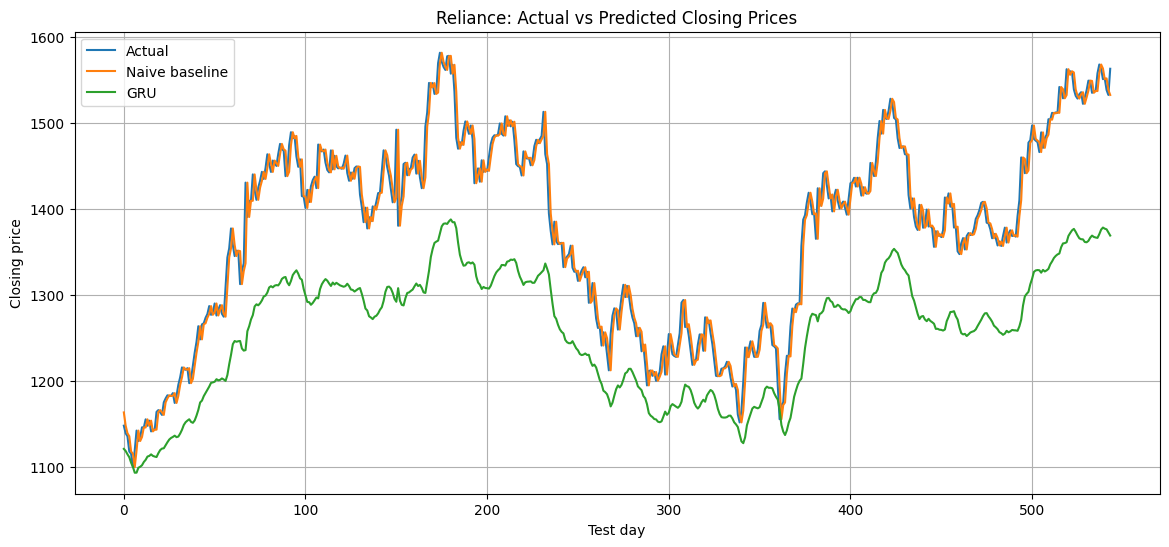

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(actual_prices, label="Actual")
plt.plot(naive_pred, label="Naive baseline")
plt.plot(gru_pred, label="GRU")

plt.title("Reliance: Actual vs Predicted Closing Prices")
plt.xlabel("Test day")
plt.ylabel("Closing price")
plt.legend()
plt.grid(True)
plt.show()

In [110]:

import numpy as np
import pandas as pd

gru_pred = np.asarray(predictions["GRU"]).ravel()
actual_prices = np.asarray(test_close).ravel()

check = pd.DataFrame({
    "Actual": actual_prices,
    "GRU_Prediction": gru_pred,
    "Error": gru_pred - actual_prices,
    "Absolute_Error": np.abs(gru_pred - actual_prices)
})

print("First 10 rows:")
display(check.head(10))

print("Last 10 rows:")
display(check.tail(10))

print("10 largest errors:")
display(check.nlargest(10, "Absolute_Error"))


First 10 rows:


,Actual,GRU_Prediction,Error,Absolute_Error
0,1148.154175,1121.175293,-26.978882,26.978882
1,1139.335449,1118.700439,-20.635010,20.635010
2,1135.852539,1114.879028,-20.973511,20.973511
3,1118.116333,1111.482300,-6.634033,6.634033
4,1115.522583,1105.110474,-10.412109,10.412109
5,1099.984985,1100.245972,0.260986,0.260986
6,1119.400879,1093.467407,-25.933472,25.933472
7,1142.472656,1093.545410,-48.927246,48.927246
8,1130.319214,1099.235840,-31.083374,31.083374
9,1135.012573,1100.394653,-34.617920,34.617920


Last 10 rows:


,Actual,GRU_Prediction,Error,Absolute_Error
534,1537.292236,1367.616089,-169.676147,169.676147
535,1537.292236,1366.958496,-170.333740,170.333740
536,1557.896851,1366.520874,-191.375977,191.375977
537,1568.149536,1370.874146,-197.275391,197.275391
538,1563.471069,1376.128174,-187.342896,187.342896
539,1551.028687,1378.540527,-172.488159,172.488159
540,1552.024048,1377.239014,-174.785034,174.785034
541,1538.486694,1376.490845,-161.995850,161.995850
542,1532.713379,1372.932129,-159.781250,159.781250
543,1563.172607,1369.239258,-193.933350,193.933350


10 largest errors:


,Actual,GRU_Prediction,Error,Absolute_Error
168,1546.747437,1328.256104,-218.491333,218.491333
174,1581.824463,1371.653931,-210.170532,210.170532
173,1569.695679,1363.331909,-206.363770,206.363770
519,1562.674805,1361.423462,-201.251343,201.251343
150,1492.328613,1292.241577,-200.087036,200.087036
537,1568.149536,1370.874146,-197.275391,197.275391
169,1541.559937,1344.312134,-197.247803,197.247803
167,1512.312622,1315.617188,-196.695435,196.695435
178,1577.699219,1382.762939,-194.936279,194.936279
67,1430.795654,1236.038086,-194.757568,194.757568


In [111]:
!pip install -q autogluon.timeseries

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [119]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

close_prices = df["Close"].to_numpy(dtype=np.float32)

train_close = close_prices[:split_idx]
test_close = close_prices[split_idx:]

# Naive prediction: tomorrow's price = today's actual price
naive_pred = np.concatenate([
    train_close[-1:],
    test_close[:-1]
])

actual = test_close

print("Test observations:", len(actual))
print("Naive predictions:", len(naive_pred))

Test observations: 544
Naive predictions: 544


In [120]:
chronos_predictions = {}

for days in [30, 60]:

    contexts = np.stack([
        close_prices[i-days:i]
        for i in range(split_idx, len(close_prices))
    ])

    context_tensor = torch.tensor(
        contexts, dtype=torch.float32
    )

    with torch.no_grad():
        forecast = chronos.predict(
            context_tensor,
            prediction_length=1
        )

    # Median forecast
    pred = forecast[:, 4, 0].cpu().numpy()

    chronos_predictions[days] = pred

    print(f"{days}-day context predictions:", len(pred))

30-day context predictions: 544
60-day context predictions: 544


In [121]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

# Naive baseline
results.append({
    "Model": "Naive",
    "Context": "-",
    "MAE": mean_absolute_error(actual, naive_pred),
    "RMSE": np.sqrt(mean_squared_error(actual, naive_pred))
})

# Chronos with 30- and 60-day contexts
for days in [30, 60]:
    pred = chronos_predictions[days]

    results.append({
        "Model": "Chronos",
        "Context": f"{days} days",
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred))
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Context,MAE,RMSE
0,Naive,-,12.885,17.915
1,Chronos,30 days,14.267,19.173
2,Chronos,60 days,13.881,19.015


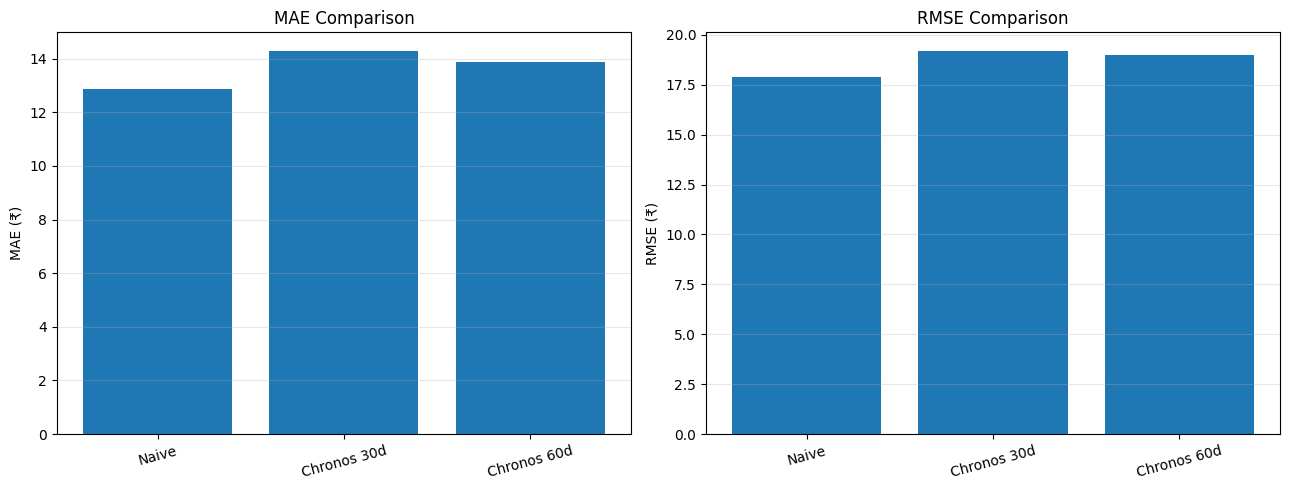

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels = ["Naive", "Chronos 30d", "Chronos 60d"]
mae_values = [
    results_df.iloc[0]["MAE"],
    results_df.iloc[1]["MAE"],
    results_df.iloc[2]["MAE"]
]
rmse_values = [
    results_df.iloc[0]["RMSE"],
    results_df.iloc[1]["RMSE"],
    results_df.iloc[2]["RMSE"]
]

axes[0].bar(labels, mae_values)
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE (₹)")

axes[1].bar(labels, rmse_values)
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE (₹)")

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

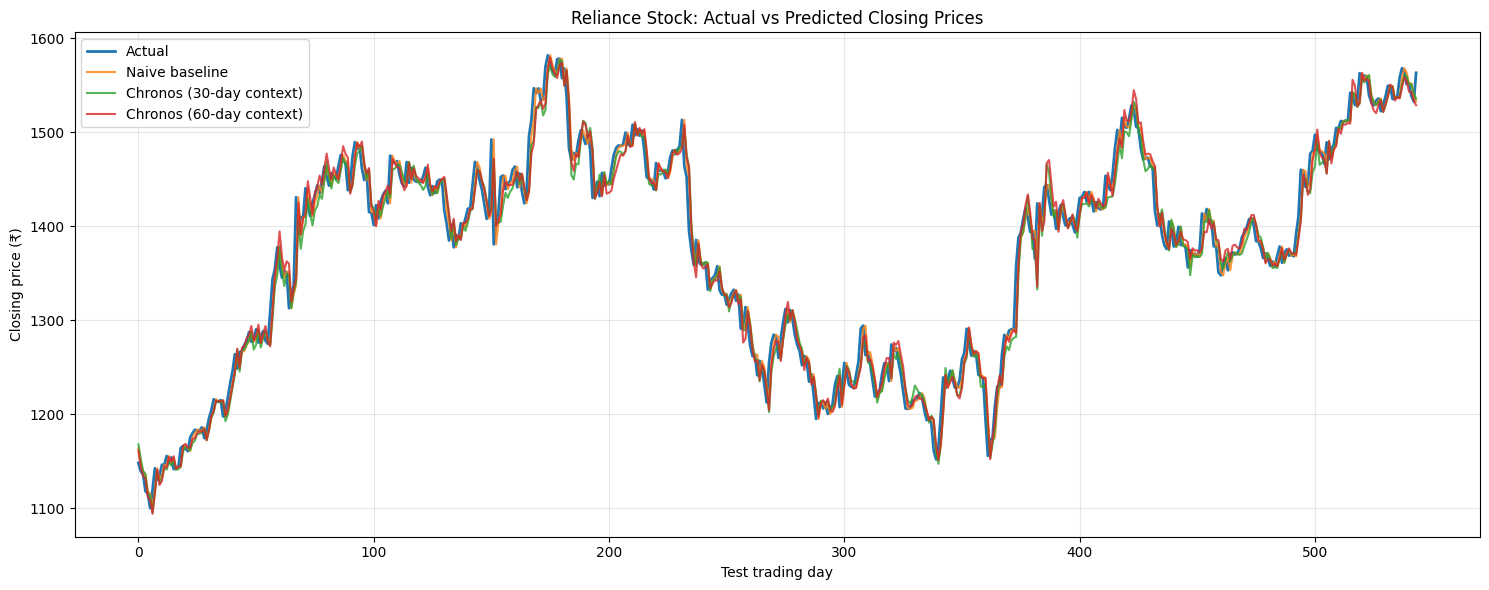

In [123]:
plt.figure(figsize=(15, 6))

plt.plot(actual, label="Actual", linewidth=2)
plt.plot(naive_pred, label="Naive baseline", alpha=0.8)
plt.plot(
    chronos_predictions[30],
    label="Chronos (30-day context)",
    alpha=0.8
)
plt.plot(
    chronos_predictions[60],
    label="Chronos (60-day context)",
    alpha=0.8
)

plt.title("Reliance Stock: Actual vs Predicted Closing Prices")
plt.xlabel("Test trading day")
plt.ylabel("Closing price (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [124]:


tickers = {
    "Reliance": "RELIANCE.NS",
    "TCS": "TCS.NS",
    "Infosys": "INFY.NS"
}

data = {}

for company, ticker in tickers.items():
    df_company = yf.download(
        ticker,
        period="5y",
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    close = df_company["Close"]

    # Handle yfinance versions that return a DataFrame
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]

    data[company] = close.dropna().astype(np.float32)

    print(company, "observations:", len(data[company]))

Reliance observations: 1237
TCS observations: 1237
Infosys observations: 1237


In [125]:
results = {}

for company, series in data.items():

    prices = series.to_numpy(dtype=np.float32)
    dates = series.index

    split_idx = int(len(prices) * 0.8)

    train_close = prices[:split_idx]
    actual = prices[split_idx:]
    test_dates = dates[split_idx:]

    # Naive baseline: previous day's actual closing price
    naive_pred = np.concatenate([
        train_close[-1:],
        actual[:-1]
    ])

    # Chronos: rolling one-day forecast, using 60 past trading days
    days = 60

    contexts = np.stack([
        prices[i-days:i]
        for i in range(split_idx, len(prices))
    ])

    context_tensor = torch.tensor(
        contexts, dtype=torch.float32
    )

    with torch.no_grad():
        forecast = chronos.predict(
            context_tensor,
            prediction_length=1
        )

    # Chronos-Bolt-Tiny's median forecast
    chrono_pred = forecast[:, 4, 0].cpu().numpy()

    results[company] = {
        "dates": test_dates,
        "actual": actual,
        "naive": naive_pred,
        "chronos": chrono_pred
    }

    print(f"{company}: {len(actual)} test days completed")

Reliance: 248 test days completed
TCS: 248 test days completed
Infosys: 248 test days completed


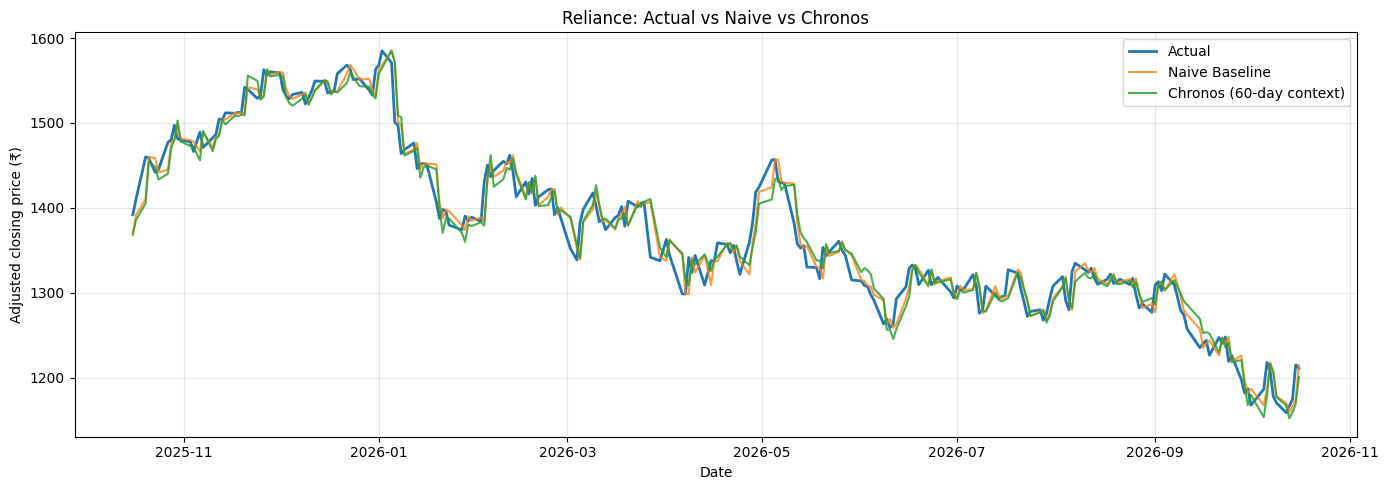

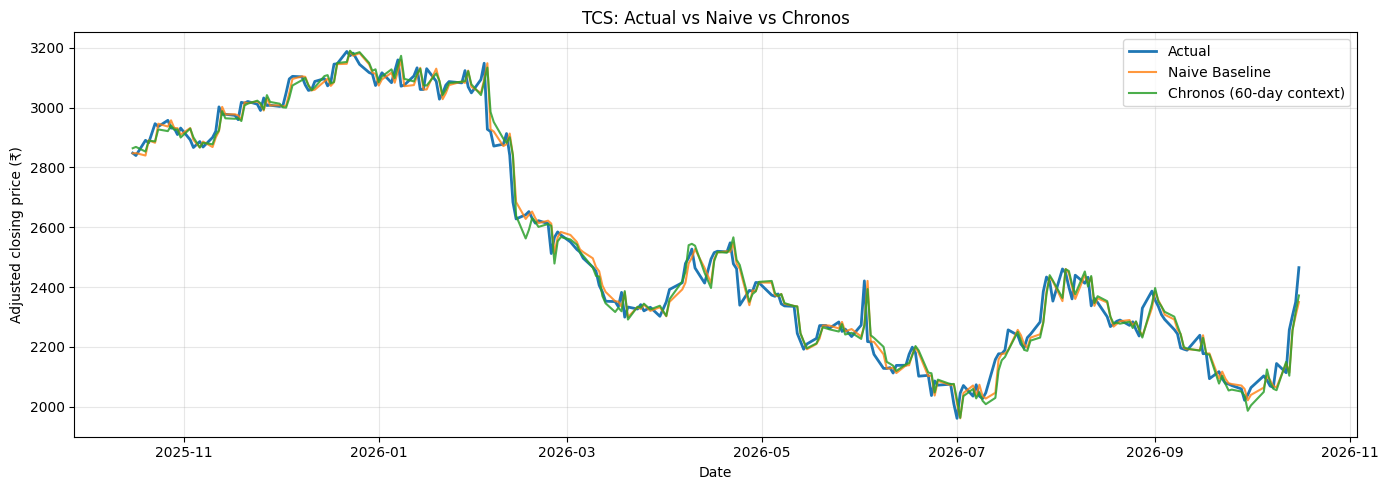

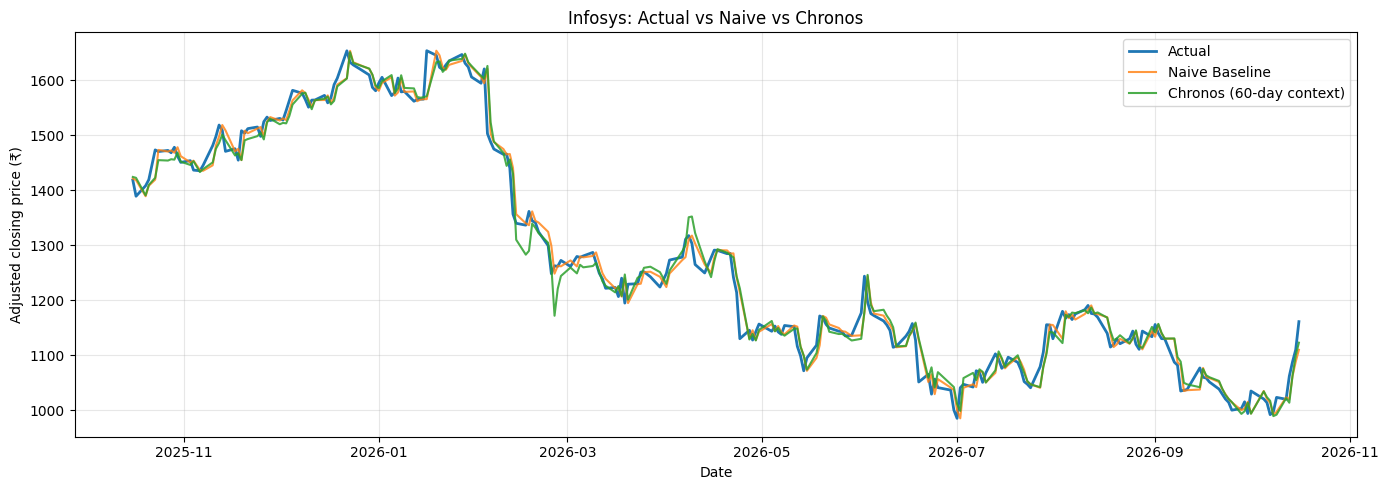

In [126]:

for company, r in results.items():

    plt.figure(figsize=(14, 5))

    plt.plot(
        r["dates"], r["actual"],
        label="Actual", linewidth=2
    )
    plt.plot(
        r["dates"], r["naive"],
        label="Naive Baseline", alpha=0.8
    )
    plt.plot(
        r["dates"], r["chronos"],
        label="Chronos (60-day context)", alpha=0.85
    )

    plt.title(f"{company}: Actual vs Naive vs Chronos")
    plt.xlabel("Date")
    plt.ylabel("Adjusted closing price (₹)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [127]:
metrics = []

for company, r in results.items():
    for model_name in ["naive", "chronos"]:
        pred = r[model_name]

        metrics.append({
            "Company": company,
            "Model": model_name.title(),
            "MAE": mean_absolute_error(r["actual"], pred),
            "RMSE": np.sqrt(
                mean_squared_error(r["actual"], pred)
            )
        })

metrics_df = pd.DataFrame(metrics)
display(metrics_df.round(2))

,Company,Model,MAE,RMSE
0,Reliance,Naive,13.97,18.50
1,Reliance,Chronos,15.79,20.08
2,TCS,Naive,32.91,46.30
3,TCS,Chronos,34.77,47.78
4,Infosys,Naive,17.64,24.40
5,Infosys,Chronos,19.31,26.38


In [128]:
for company, r in results.items():
    actual = r["actual"]

    print(f"\n{company}")

    for model in ["naive", "chronos"]:
        pred = r[model]

        mape = np.mean(
            np.abs((actual - pred) / actual)
        ) * 100

        print(f"{model.title()} MAPE: {mape:.2f}%")


Reliance
Naive MAPE: 1.03%
Chronos MAPE: 1.16%

TCS
Naive MAPE: 1.33%
Chronos MAPE: 1.41%

Infosys
Naive MAPE: 1.42%
Chronos MAPE: 1.55%


In [129]:
ticker = "RELIANCE.NS"
df_today = yf.download(
    ticker,
    period="10d",
    interval="1d",
    auto_adjust=True,
    progress=False
)

close = df_today["Close"]

# Handle different yfinance output formats
if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

close = close.dropna()

# Latest available trading day and previous trading day
yesterday_close = float(close.iloc[-2])
actual_today = float(close.iloc[-1])
predicted_today = yesterday_close

absolute_error = abs(actual_today - predicted_today)
percentage_error = absolute_error / actual_today * 100

print("Prediction date:", close.index[-1].date())
print(f"Previous close: ₹{yesterday_close:.2f}")
print(f"Predicted close: ₹{predicted_today:.2f}")
print(f"Actual latest close: ₹{actual_today:.2f}")
print(f"Absolute error: ₹{absolute_error:.2f}")
print(f"Absolute percentage error: {percentage_error:.2f}%")

Prediction date: 2026-10-16
Previous close: ₹1215.00
Predicted close: ₹1215.00
Actual latest close: ₹1211.20
Absolute error: ₹3.80
Absolute percentage error: 0.31%


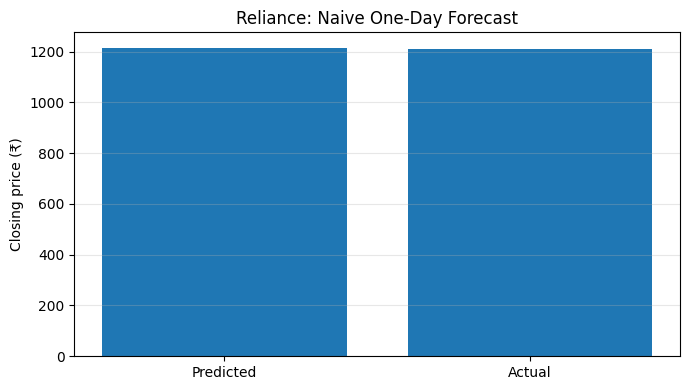

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    ["Predicted", "Actual"],
    [predicted_today, actual_today]
)

plt.title("Reliance: Naive One-Day Forecast")
plt.ylabel("Closing price (₹)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [131]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = yf.download(
    "RELIANCE.NS",
    period="3mo",
    interval="1d",
    auto_adjust=True,
    progress=False
)

close = df["Close"]

if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

close = close.dropna()

# Last 30 available closing prices
actual = close.iloc[-30:].to_numpy()

# Each prediction = previous trading day's close
predicted = close.iloc[-31:-1].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print(f"30-day MAE: ₹{mae:.2f}")
print(f"30-day RMSE: ₹{rmse:.2f}")
print(f"30-day MAPE: {mape:.2f}%")

30-day MAE: ₹15.06
30-day RMSE: ₹17.72
30-day MAPE: 1.23%


Prices available: 65
Test days: 5
Context shape: (5, 60)
Naive: MAE = ₹14.26, RMSE = ₹19.49, MAPE = 1.19%
Chronos: MAE = ₹18.96, RMSE = ₹23.43, MAPE = 1.59%


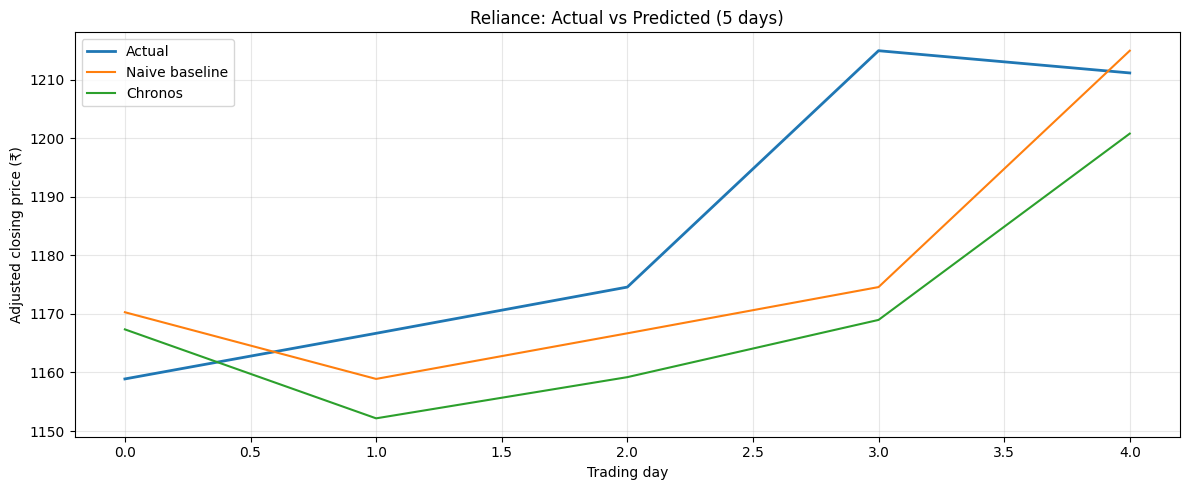

In [135]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert prices to a 1D NumPy array
prices = np.asarray(close, dtype=np.float32).reshape(-1)
prices = prices[~np.isnan(prices)]

context_days = 60
test_days = 30

# Need 60 context days + at least 1 test day
if len(prices) <= context_days:
    raise ValueError(
        f"Only {len(prices)} prices found. "
        "Download more historical data."
    )

# Automatically reduce test days if needed
test_days = min(test_days, len(prices) - context_days)

# Actual closing prices to evaluate
actual = prices[-test_days:]

# Naive prediction: previous day's closing price
naive_pred = prices[-test_days-1:-1]

# Build equally sized 60-day contexts
start_idx = len(prices) - test_days

contexts = np.array([
    prices[i-context_days:i]
    for i in range(start_idx, len(prices))
])

print("Prices available:", len(prices))
print("Test days:", test_days)
print("Context shape:", contexts.shape)

# Generate Chronos forecasts
with torch.no_grad():
    forecast = chronos.predict(
        torch.tensor(contexts, dtype=torch.float32),
        prediction_length=1
    )

chronos_pred = forecast[:, 4, 0].cpu().numpy()

# Compare both methods
for name, pred in [
    ("Naive", naive_pred),
    ("Chronos", chronos_pred)
]:
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100

    print(
        f"{name}: MAE = ₹{mae:.2f}, "
        f"RMSE = ₹{rmse:.2f}, MAPE = {mape:.2f}%"
    )

# Plot the comparison
plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual", linewidth=2)
plt.plot(naive_pred, label="Naive baseline")
plt.plot(chronos_pred, label="Chronos")
plt.title(f"Reliance: Actual vs Predicted ({test_days} days)")
plt.xlabel("Trading day")
plt.ylabel("Adjusted closing price (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Indian Stock Price Forecasting using Chronos-Bolt-Tiny**

Developed a time-series forecasting project using Python, PyTorch, and Yahoo Finance data to compare a pretrained Chronos-Bolt-Tiny model against a Naive baseline for Indian stock prices. Evaluated predictions using MAE, RMSE, and MAPE, demonstrating the importance of baseline comparisons and empirical model evaluation.